# 01. Análise Exploratória de Dados (EDA)
**Disciplina:** DCT1401 - Inteligência Artificial  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook conduz a Análise Exploratória de Dados (EDA) completa sobre a base bruta de pedidos de delivery (`food_delivery_orders_dataset.csv`), contemplando:
1. **Inspeção Inicial e Tipagem:** Dimensões exatas da base, verificação das primeiras (`head`) e últimas (`tail`) linhas, e classificação estrutural das variáveis (identificadores, temporais, categóricas nominais/ordinais e numéricas contínuas/discretas).
2. **Estatísticas Descritivas:** Tabelas completas contendo contagem, média, desvio padrão, mínimo, quartis ($Q_1$, mediana $Q_2$, $Q_3$), máximo, intervalo interquartil (IQR) e assimetria (*skewness*), além das distribuições de frequência absoluta e relativa (%) das variáveis categóricas.
3. **Mapeamento de Valores Ausentes:** Quantificação exata e percentual por coluna, visualização matricial e diagnóstico operacional do mecanismo gerador de ausência (pedidos cancelados vs. concluídos).
4. **Detecção Sistemática de Outliers (Método IQR):** Cálculo dos limites matemáticos $[Q_1 - 1{,}5 \times \text{IQR},\; Q_3 + 1{,}5 \times \text{IQR}]$, contagem absoluta e percentual de registros atípicos em todas as variáveis numéricas e fundamentação operacional.
5. **Análise de Correlação e Multicolinearidade:** Matriz de correlação de Pearson ($r$), listagem exata de todos os pares com $|r| \ge 0{,}50$, análise das relações com os alvos de regressão (`actual_delivery_time_minutes`) e classificação (`late_delivery`), e diagnóstico de redundância entre variáveis financeiras.
6. **Painel de Visualizações Exploratórias:** Gráficos de distribuição (histogramas com KDE), gráficos de barras das categorias e análises bivariadas (*scatter plots* e *boxplots* estratificados por clima, trânsito e status de atraso).


## 1. Carregamento e Inspeção Inicial do Dataset
Carregamos o arquivo original intacto a partir de `../data/raw/food_delivery_orders_dataset.csv`, convertemos os atributos temporais (`order_timestamp` e `order_date`) para o tipo `datetime64` e inspecionamos a dimensão $(N \times p)$, os primeiros 5 registros (`head`) e os últimos 5 registros (`tail`).

In [1]:
from IPython.display import display
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Adiciona o diretório raiz ao path para importar módulos de src/
sys.path.append("..")
from src.eda import (
    check_missing_values,
    summary_statistics,
    detect_outliers_iqr,
    get_high_correlation_pairs
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

# Carregamento do dataset bruto
caminho_arquivo = "../data/raw/food_delivery_orders_dataset.csv"
df = pd.read_csv(caminho_arquivo)

print(f"Dimensões exatas do dataset bruto: {df.shape[0]:,} linhas x {df.shape[1]} colunas.")


Dimensões exatas do dataset bruto: 50,000 linhas x 37 colunas.


In [2]:
print("=== PRIMEIRAS 5 LINHAS (HEAD) ===")
display(df.head(5))

print("\n=== ÚLTIMAS 5 LINHAS (TAIL) ===")
display(df.tail(5))


=== PRIMEIRAS 5 LINHAS (HEAD) ===


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.4,4,64.82,0,9.07,2.40,0.00,76.29,Credit Card,11.36,1.1,Rain,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.4,2,13.03,0,1.82,0.84,3.25,18.94,Cash,1.09,2.5,Cloudy,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.8,1,10.12,10,1.28,0.56,7.90,18.85,Cash,0.00,11.8,Cloudy,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,Local,3.9,1,8.86,10,1.12,0.40,4.70,14.19,Digital Wallet,0.00,5.4,Cloudy,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,Pizza,3.5,1,15.08,20,1.69,0.65,5.05,19.45,Credit Card,1.70,6.1,Rain,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9



=== ÚLTIMAS 5 LINHAS (TAIL) ===


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
49995,ORD_049996,CUS_00280,RES_0130,DRV_0112,2025-10-25 12:16:00,2025-10-25,12,Saturday,1,City_B,City_B_Area_4,36,Regular,Fast Food,Local,4.6,1,8.87,20,0.99,0.29,3.45,11.83,Credit Card,1.54,2.9,Cloudy,Medium,34,5.0,11,19,21.0,0.0,Completed,NaN,4.4
49996,ORD_049997,CUS_00893,RES_0028,DRV_0036,2025-10-05 19:48:00,2025-10-05,19,Sunday,1,City_B,City_B_Area_10,18,Regular,Casual Dining,Burger,3.2,1,14.57,0,2.04,0.49,3.90,21.00,Credit Card,0.00,3.8,Clear,High,49,5.0,9,28,29.0,0.0,Completed,NaN,4.8
49997,ORD_049998,CUS_01618,RES_0001,DRV_0071,2025-10-08 12:18:00,2025-10-08,12,Wednesday,0,City_A,City_A_Area_4,29,Regular,Fast Food,Local,3.9,1,8.48,0,1.19,0.40,3.05,13.12,Credit Card,1.47,2.1,Clear,High,54,4.1,11,18,16.0,0.0,Completed,NaN,4.7
49998,ORD_049999,CUS_00025,RES_0057,DRV_0103,2025-10-20 17:39:00,2025-10-20,17,Monday,0,City_A,City_A_Area_7,25,Regular,Casual Dining,Pizza,4.6,1,14.47,0,2.03,0.45,2.75,19.70,Digital Wallet,0.00,1.5,Clear,High,33,4.0,20,17,27.0,1.0,Completed,NaN,3.8
49999,ORD_050000,CUS_00038,RES_0139,DRV_0131,2025-10-13 17:36:00,2025-10-13,17,Monday,0,City_A,City_A_Area_5,33,New,Casual Dining,Burger,4.2,1,14.22,20,1.59,0.37,5.65,18.99,Cash,0.00,7.3,Rain,Low,44,4.7,12,30,40.0,1.0,Completed,NaN,4.5


In [3]:
# Conversão explícita das colunas temporais para verificação de integridade
df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])
df["order_date"] = pd.to_datetime(df["order_date"])

# Resumo estrutural de tipos e preenchimento por coluna
info_df = pd.DataFrame({
    "Coluna": df.columns,
    "Tipo_Dado (dtype)": [str(t) for t in df.dtypes],
    "Nao_Nulos": df.notnull().sum().values,
    "Nulos": df.isnull().sum().values,
    "%_Preenchido": ((df.notnull().sum().values / len(df)) * 100).round(2),
    "Valores_Unicos": [df[col].nunique() for col in df.columns]
})

print("=== ESTRUTURA E TIPAGEM DAS 37 COLUNAS ===")
display(info_df)


=== ESTRUTURA E TIPAGEM DAS 37 COLUNAS ===


,Coluna,Tipo_Dado (dtype),Nao_Nulos,Nulos,%_Preenchido,Valores_Unicos
0,order_id,str,50000,0,100.00,50000
1,customer_id,str,50000,0,100.00,4979
2,restaurant_id,str,50000,0,100.00,250
3,driver_id,str,50000,0,100.00,200
4,order_timestamp,datetime64[us],50000,0,100.00,25459
5,order_date,datetime64[us],50000,0,100.00,30
6,order_hour,int64,50000,0,100.00,24
7,day_of_week,str,50000,0,100.00,7
8,is_weekend,int64,50000,0,100.00,2
9,city,str,50000,0,100.00,4


## 2. Estatísticas Descritivas (Variáveis Numéricas e Categóricas)
A tabela a seguir apresenta as medidas de tendência central (média e mediana/$50\%$), dispersão (desvio padrão, mínimo, máximo, quartis $25\%$ e $75\%$, e intervalo interquartil $\text{IQR} = Q_3 - Q_1$) e forma da distribuição (assimetria/*skewness*) para todas as 20 variáveis numéricas do dataset. Em seguida, exibimos as tabelas de frequência absoluta e relativa (\%) das variáveis categóricas operacionais.

In [4]:
tabela_estatisticas = summary_statistics(df)
tabela_estatisticas.to_csv("../reports/tables/eda_summary_statistics.csv")

print("=== TABELA COMPLETA DE ESTATÍSTICAS DESCRITIVAS (VARIÁVEIS NUMÉRICAS) ===")
display(tabela_estatisticas)


=== TABELA COMPLETA DE ESTATÍSTICAS DESCRITIVAS (VARIÁVEIS NUMÉRICAS) ===


,count,mean,std,min,25%,50%,75%,max,IQR,skewness
order_hour,50000.0,14.47,5.23,0.00,11.00,14.00,19.00,23.00,8.00,-0.46
is_weekend,50000.0,0.27,0.44,0.00,0.00,0.00,1.00,1.00,1.00,1.05
customer_age,50000.0,27.69,7.54,18.00,21.00,27.00,33.00,55.00,12.00,0.51
restaurant_rating,50000.0,4.21,0.45,2.80,3.90,4.20,4.60,5.00,0.70,-0.09
items_count,50000.0,2.91,2.03,1.00,1.00,2.00,4.00,10.00,3.00,1.26
subtotal,50000.0,30.90,27.07,5.10,13.10,22.82,40.12,362.98,27.02,2.71
discount_percent,50000.0,4.50,6.43,0.00,0.00,0.00,10.00,20.00,10.00,1.15
tax_amount,50000.0,4.13,3.64,0.57,1.73,2.89,5.39,50.82,3.66,2.74
service_fee,50000.0,1.47,1.38,0.13,0.58,1.04,1.89,25.21,1.31,3.05
delivery_fee,50000.0,3.08,2.30,0.00,0.00,3.50,4.50,12.00,4.50,0.10


In [5]:
colunas_categoricas = [
    "order_status",
    "weather",
    "traffic_level",
    "customer_type",
    "restaurant_type",
    "restaurant_primary_category",
    "payment_method",
    "day_of_week",
    "city"
]

print("=== DISTRIBUIÇÃO DE FREQUÊNCIA DAS VARIÁVEIS CATEGÓRICAS ===")
for col in colunas_categoricas:
    freq_df = pd.DataFrame({
        "Contagem_Absoluta": df[col].value_counts(dropna=False),
        "Frequencia_Relativa (%)": (df[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    })
    print(f"\n--- Coluna: {col} (Total de categorias: {df[col].nunique()}) ---")
    display(freq_df)


=== DISTRIBUIÇÃO DE FREQUÊNCIA DAS VARIÁVEIS CATEGÓRICAS ===

--- Coluna: order_status (Total de categorias: 2) ---


,Contagem_Absoluta,Frequencia_Relativa (%)
order_status,,
Completed,49132,98.26
Cancelled,868,1.74



--- Coluna: weather (Total de categorias: 4) ---


,Contagem_Absoluta,Frequencia_Relativa (%)
weather,,
Clear,28248,56.50
Cloudy,12810,25.62
Rain,7627,15.25
Storm,1315,2.63



--- Coluna: traffic_level (Total de categorias: 3) ---


...

,Contagem_Absoluta,Frequencia_Relativa (%)
payment_method,,
Credit Card,24971,49.94
Cash,15050,30.10
Digital Wallet,9979,19.96



--- Coluna: day_of_week (Total de categorias: 7) ---


,Contagem_Absoluta,Frequencia_Relativa (%)
day_of_week,,
Thursday,8472,16.94
Wednesday,8212,16.42
Saturday,6698,13.40
Tuesday,6671,13.34
Monday,6665,13.33
Sunday,6658,13.32
Friday,6624,13.25



--- Coluna: city (Total de categorias: 4) ---


,Contagem_Absoluta,Frequencia_Relativa (%)
city,,
City_A,19888,39.78
City_B,14885,29.77
City_C,10178,20.36
City_D,5049,10.10


## 3. Identificação e Diagnóstico de Valores Ausentes
Analisamos a quantidade exata e a proporção percentual de valores ausentes em todo o dataset.

### Diagnóstico Estrutural dos Dados Ausentes:
1. **`cancellation_reason` (49.132 ausentes / 98,26%):** Esta coluna registra o motivo de cancelamento do pedido. Ela está ausente em exatamente 49.132 registros porque esses pedidos foram **entregues com sucesso** (`order_status == 'Delivered'`). Apenas os 868 pedidos cancelados (`1,74%`) possuem motivo de cancelamento preenchido.
2. **`actual_delivery_time_minutes`, `late_delivery`, `tip_amount` e `customer_rating` (868 ausentes cada / 1,74%):** Os valores nulos nestas quatro colunas ocorrem exatamente nas mesmas 868 linhas correspondentes aos pedidos **cancelados** (`order_status == 'Cancelled'`). Como a entrega não se concretizou, não existe tempo real de entrega, indicador de atraso, gorjeta final ou avaliação do cliente.
3. **Implicação para Modelagem:** Manter pedidos cancelados ou imputar valores artificiais no alvo (`actual_delivery_time_minutes` ou `late_delivery`) introduziria ruído artificial na variável dependente. Assim, na etapa de limpeza, a coluna `cancellation_reason` deve ser descartada (além de ser informação pós-evento) e os 868 registros cancelados devem ser removidos, restando 49.132 pedidos concluídos sem nenhum valor ausente nas demais colunas.

=== TABELA DE VALORES AUSENTES POR COLUNA ===


,Tipo,Valores_Ausentes,Valores_Preenchidos,Porcentagem_Ausente (%)
cancellation_reason,str,49132,868,98.26
tip_amount,float64,868,49132,1.74
actual_delivery_time_minutes,float64,868,49132,1.74
late_delivery,float64,868,49132,1.74
customer_rating,float64,868,49132,1.74



=== RELAÇÃO ENTRE ORDER_STATUS E VALORES AUSENTES ===


,actual_delivery_time_minutes,late_delivery,tip_amount,customer_rating,cancellation_reason
order_status,,,,,
Cancelled,868,868,868,868,0
Completed,0,0,0,0,49132


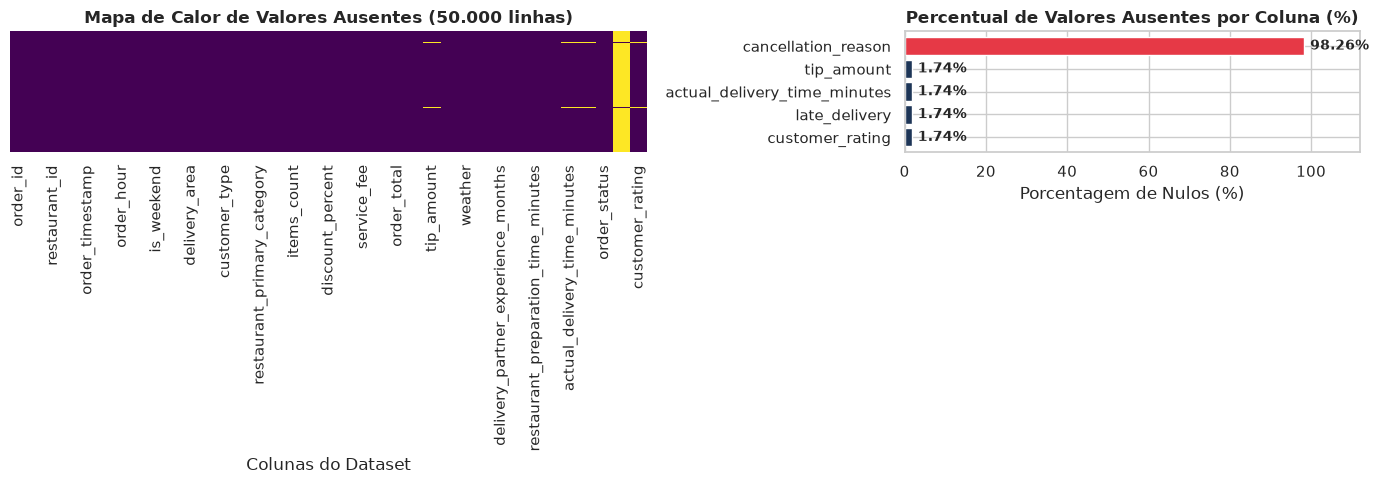

In [6]:
tabela_ausentes = check_missing_values(df)
tabela_ausentes.to_csv("../reports/tables/eda_missing_values.csv")

print("=== TABELA DE VALORES AUSENTES POR COLUNA ===")
display(tabela_ausentes)

# Verificação cruzada com order_status
print("\n=== RELAÇÃO ENTRE ORDER_STATUS E VALORES AUSENTES ===")
cruzamento_status = df.groupby("order_status")[
    ["actual_delivery_time_minutes", "late_delivery", "tip_amount", "customer_rating", "cancellation_reason"]
].apply(lambda g: g.isnull().sum())
display(cruzamento_status)

# Figura: Mapa de calor + Gráfico de barras de % de ausentes
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})

sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False, ax=axes[0])
axes[0].set_title("Mapa de Calor de Valores Ausentes (50.000 linhas)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Colunas do Dataset")

bars = axes[1].barh(
    tabela_ausentes.index[::-1],
    tabela_ausentes["Porcentagem_Ausente (%)"][::-1],
    color=["#1d3557", "#1d3557", "#1d3557", "#1d3557", "#e63946"]
)
axes[1].set_title("Percentual de Valores Ausentes por Coluna (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Porcentagem de Nulos (%)")
axes[1].set_xlim(0, 112)
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("../reports/figures/missing_values.png", dpi=300)
plt.show()


## 4. Detecção Sistemática de Outliers (Método IQR)
Aplicamos o critério de Tukey baseado no Intervalo Interquartil ($\text{IQR} = Q_3 - Q_1$), definindo como discrepantes os valores situados fora do intervalo:
$$\text{Limite Inferior} = Q_1 - 1{,}5 \times \text{IQR}, \qquad \text{Limite Superior} = Q_3 + 1{,}5 \times \text{IQR}$$

A tabela abaixo contabiliza o número exato e o percentual de outliers para cada variável numérica contínua/discreta do dataset.
- Na variável alvo de regressão (`actual_delivery_time_minutes`), temos $Q_1 = 25{,}00$ min, Mediana $= 33{,}00$ min, $Q_3 = 42{,}00$ min e $\text{IQR} = 17{,}00$ min, resultando em limite superior de $67{,}50$ min e **1.657 outliers (3,37% dos pedidos entregues)**, chegando até o máximo de $172{,}00$ min.
- Nas variáveis financeiras (`subtotal`, `tax_amount`, `service_fee`, `order_total`), cerca de **5,19% a 5,73%** dos pedidos (entre 2.594 e 2.863 registros) configuram outliers superiores, representando pedidos de grande porte (ex.: refeições familiares ou corporativas).
- Em `distance_km`, há **2.173 outliers (4,35%)** acima de $10{,}55$ km (chegando a $20{,}00$ km), correspondendo a entregas em zonas periféricas ou mais afastadas dos centros gastronômicos.

=== TABELA DE CONTAGEM E LIMITES DE OUTLIERS (MÉTODO IQR) ===


,Variavel,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Limite_Inferior,Limite_Superior,Outliers_Abaixo,Outliers_Acima,Total_Outliers,Porcentagem (%)
0,tip_amount,0.00,0.00,2.28,2.28,-3.42,5.70,0,3913,3913,7.96
1,service_fee,0.58,1.04,1.89,1.31,-1.39,3.86,0,2863,2863,5.73
2,subtotal,13.10,22.82,40.12,27.02,-27.43,80.65,0,2667,2667,5.33
3,order_total,17.43,28.35,48.66,31.23,-29.42,95.50,0,2613,2613,5.23
4,tax_amount,1.73,2.89,5.39,3.66,-3.76,10.88,0,2594,2594,5.19
5,distance_km,2.80,4.10,5.90,3.10,-1.85,10.55,0,2173,2173,4.35
6,estimated_delivery_time_minutes,22.00,28.00,37.00,15.00,-0.50,59.50,0,1758,1758,3.52
7,actual_delivery_time_minutes,25.00,33.00,42.00,17.00,-0.50,67.50,0,1657,1657,3.37
8,restaurant_preparation_time_minutes,10.00,14.00,19.00,9.00,-3.50,32.50,0,1468,1468,2.94
9,items_count,1.00,2.00,4.00,3.00,-3.50,8.50,0,994,994,1.99


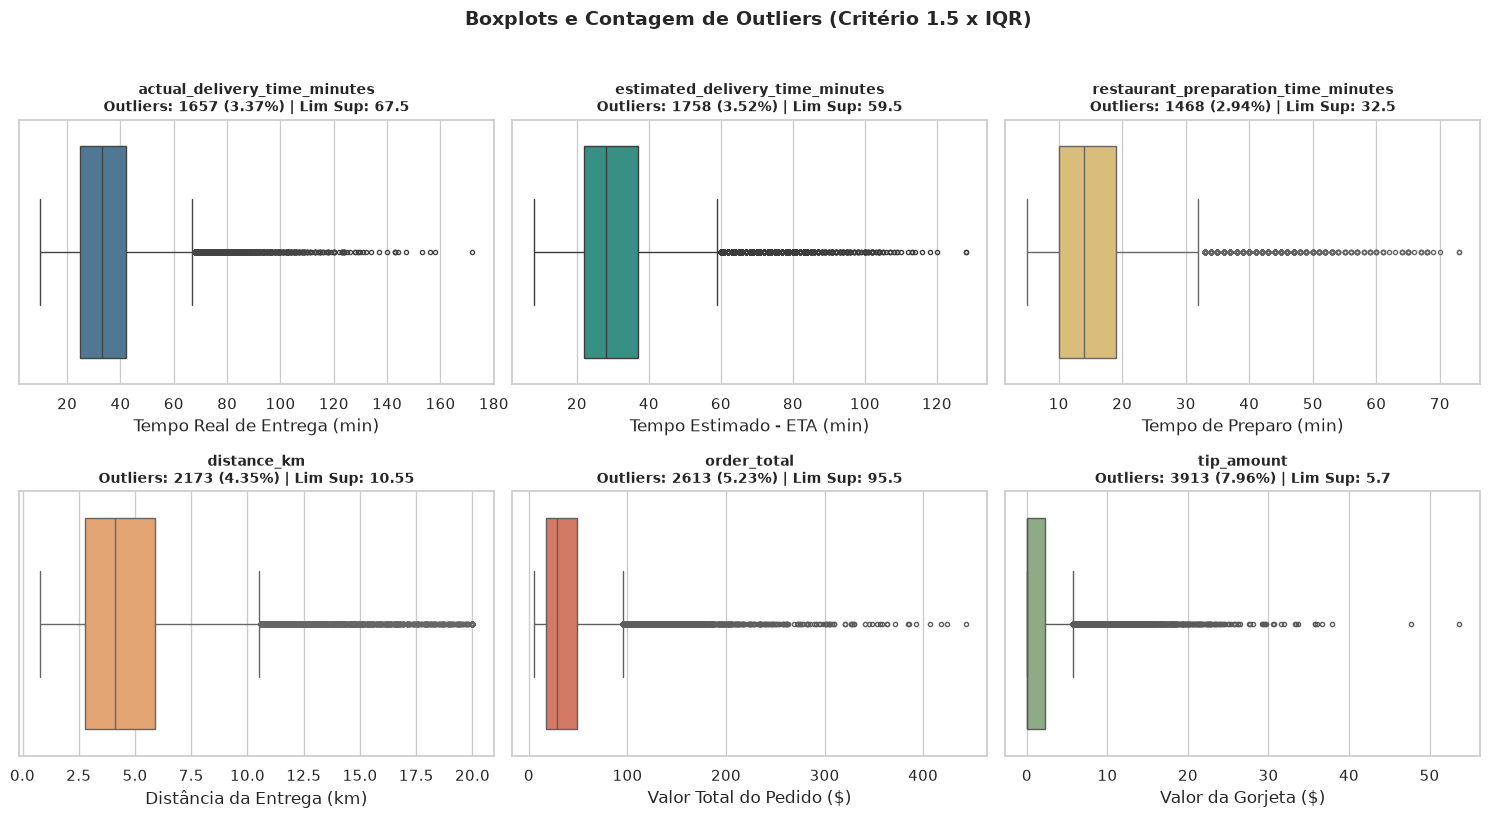

In [7]:
tabela_outliers = detect_outliers_iqr(df)
tabela_outliers.to_csv("../reports/tables/eda_outliers_iqr.csv", index=False)

print("=== TABELA DE CONTAGEM E LIMITES DE OUTLIERS (MÉTODO IQR) ===")
display(tabela_outliers)

# Visualização de Boxplots das principais variáveis operacionais e financeiras
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols_plot = [
    ("actual_delivery_time_minutes", "Tempo Real de Entrega (min)", "#457b9d"),
    ("estimated_delivery_time_minutes", "Tempo Estimado - ETA (min)", "#2a9d8f"),
    ("restaurant_preparation_time_minutes", "Tempo de Preparo (min)", "#e9c46a"),
    ("distance_km", "Distância da Entrega (km)", "#f4a261"),
    ("order_total", "Valor Total do Pedido ($)", "#e76f51"),
    ("tip_amount", "Valor da Gorjeta ($)", "#8ab17d")
]

for ax, (col, label, color) in zip(axes.flatten(), cols_plot):
    sns.boxplot(x=df[col].dropna(), ax=ax, color=color, fliersize=3)
    row_info = tabela_outliers[tabela_outliers["Variavel"] == col].iloc[0]
    ax.set_title(
        f"{col}\nOutliers: {row_info['Total_Outliers']} ({row_info['Porcentagem (%)']:.2f}%) | Lim Sup: {row_info['Limite_Superior']}",
        fontsize=10, fontweight="bold"
    )
    ax.set_xlabel(label)

plt.suptitle("Boxplots e Contagem de Outliers (Critério 1.5 x IQR)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/outliers_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Análise de Correlação e Multicolinearidade
Calculamos a matriz de correlação linear de Pearson ($r$) entre todas as variáveis numéricas e listamos explicitamente todos os pares com correlação forte ou moderada ($|r| \ge 0{,}50$).

### Principais Achados Numéricos:
1. **Multicolinearidade severa no bloco financeiro:**
   - `order_total` $\leftrightarrow$ `tax_amount`: $r = 0{,}9971$
   - `tax_amount` $\leftrightarrow$ `subtotal`: $r = 0{,}9947$
   - `order_total` $\leftrightarrow$ `subtotal`: $r = 0{,}9919$
   - `order_total` $\leftrightarrow$ `service_fee`: $r = 0{,}9464$
   - `service_fee` $\leftrightarrow$ `tax_amount`: $r = 0{,}9442$
   - `service_fee` $\leftrightarrow$ `subtotal`: $r = 0{,}9400$
   Isso ocorre porque impostos (`tax_amount`) e taxa de serviço (`service_fee`) são percentuais diretos sobre o `subtotal`. Manter todas essas variáveis simultaneamente em modelos lineares infla a variância dos estimadores (multicolinearidade) e, em modelos baseados em árvores, dilui a importância real do tamanho do pedido entre variáveis colineares.
2. **Relação entre Tamanho do Pedido e Tempo de Preparo:**
   - `restaurant_preparation_time_minutes` apresenta alta correlação com `subtotal` ($r = 0{,}8688$), `order_total` ($r = 0{,}8621$) e `items_count` ($r = 0{,}7436$), pois pedidos maiores demandam mais tempo de cozinha.
3. **Correlações com o Alvo de Regressão (`actual_delivery_time_minutes`):**
   - `estimated_delivery_time_minutes`: $r = 0{,}9295$
   - `distance_km`: $r = 0{,}7674$
   - `restaurant_preparation_time_minutes`: $r = 0{,}5015$
   - `order_total`: $r = 0{,}4610$ | `items_count`: $r = 0{,}3761$ | `delivery_fee`: $r = 0{,}3404$
4. **Correlações com o Alvo de Classificação (`late_delivery`) e Vazamento de Dados (*Data Leakage*):**
   - `customer_rating` possui correlação negativa forte com `late_delivery` ($r = -0{,}6656$) e moderada com `actual_delivery_time_minutes` ($r = -0{,}3195$), pois clientes penalizam entregas atrasadas na avaliação pós-entrega. Contudo, **`customer_rating` e `tip_amount` são variáveis pós-entrega (indisponíveis no momento do pedido)** e devem ser removidas da modelagem preditiva para evitar vazamento de dados (*data leakage*).

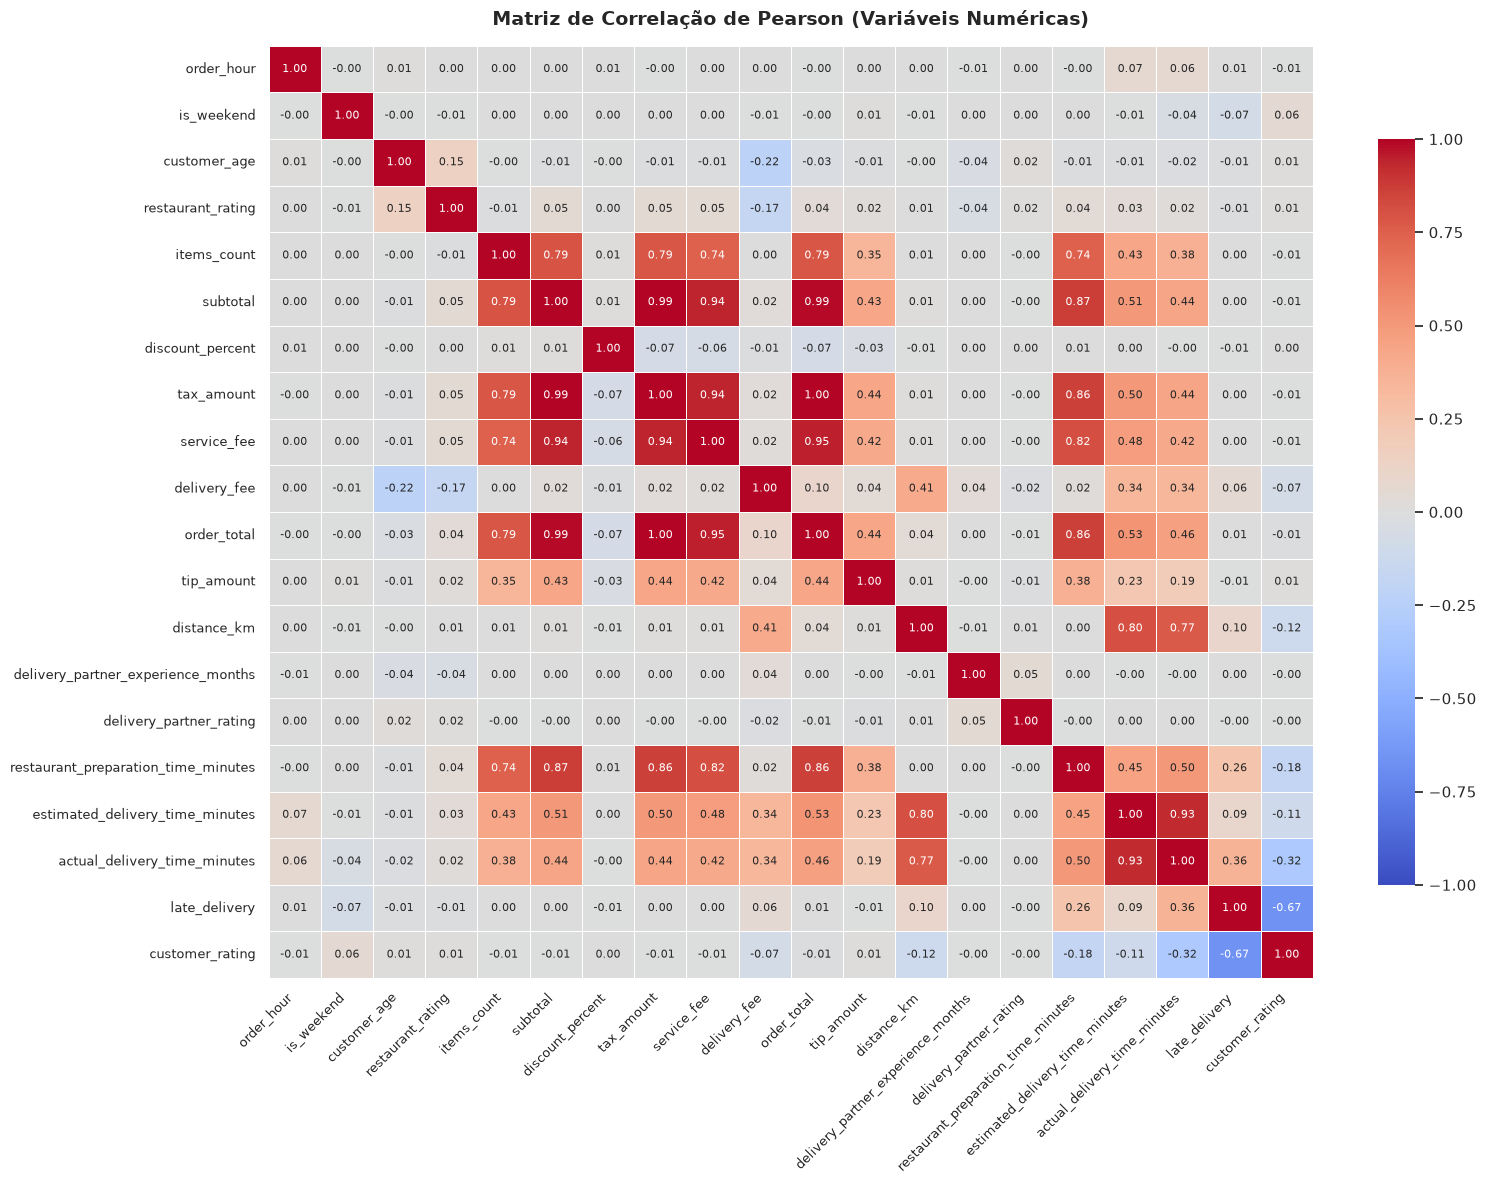

=== PARES DE VARIÁVEIS COM CORRELAÇÃO DE PEARSON |r| >= 0.50 ===


,Variavel_1,Variavel_2,Correlacao_Pearson (r),Correlacao_Absoluta (|r|)
0,order_total,tax_amount,0.9971,0.9971
1,tax_amount,subtotal,0.9947,0.9947
2,order_total,subtotal,0.9919,0.9919
3,order_total,service_fee,0.9464,0.9464
4,service_fee,tax_amount,0.9442,0.9442
5,service_fee,subtotal,0.9400,0.9400
6,actual_delivery_time_minutes,estimated_delivery_time_minutes,0.9295,0.9295
7,restaurant_preparation_time_minutes,subtotal,0.8688,0.8688
8,restaurant_preparation_time_minutes,tax_amount,0.8644,0.8644
9,restaurant_preparation_time_minutes,order_total,0.8621,0.8621



=== CORRELAÇÃO DE PEARSON COM OS ALVOS DE REGRESSÃO E CLASSIFICAÇÃO ===


,Corr_Tempo_Real (actual_delivery_time_minutes),Corr_Atraso (late_delivery)
actual_delivery_time_minutes,1.0000,0.3594
estimated_delivery_time_minutes,0.9295,0.0883
distance_km,0.7674,0.0977
restaurant_preparation_time_minutes,0.5015,0.2552
order_total,0.4610,0.0078
subtotal,0.4400,0.0026
tax_amount,0.4377,0.0032
service_fee,0.4152,0.0034
items_count,0.3761,0.0021
late_delivery,0.3594,1.0000


In [8]:
df_numeric = df.select_dtypes(include=[np.number])
matriz_corr = df_numeric.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matriz de Correlação de Pearson (Variáveis Numéricas)", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig("../reports/figures/correlation_matrix.png", dpi=300)
plt.show()

# Tabela exata de pares com |r| >= 0.50
pares_corr = get_high_correlation_pairs(df, threshold=0.50)
pares_corr.to_csv("../reports/tables/eda_high_correlations.csv", index=False)

print("=== PARES DE VARIÁVEIS COM CORRELAÇÃO DE PEARSON |r| >= 0.50 ===")
display(pares_corr)

# Tabela de correlação específica com os dois alvos do projeto
corr_alvos = pd.DataFrame({
    "Corr_Tempo_Real (actual_delivery_time_minutes)": matriz_corr["actual_delivery_time_minutes"].round(4),
    "Corr_Atraso (late_delivery)": matriz_corr["late_delivery"].round(4)
}).sort_values(by="Corr_Tempo_Real (actual_delivery_time_minutes)", ascending=False)

print("\n=== CORRELAÇÃO DE PEARSON COM OS ALVOS DE REGRESSÃO E CLASSIFICAÇÃO ===")
display(corr_alvos)


## 6. Painel Completo de Visualizações Exploratórias
Construímos e salvamos as visualizações gráficas para documentar as distribuições univariadas e as relações bivariadas com os alvos:
1. **Histogramas com Curvas de Densidade (KDE):** Distribuições de `actual_delivery_time_minutes`, `distance_km`, `restaurant_preparation_time_minutes` e `subtotal` (`eda_histograms.png`).
2. **Distribuição das Variáveis Categóricas e Taxa de Atraso:** Frequência de pedidos por categoria de restaurante (`restaurant_categories.png`), clima (`weather`), nível de trânsito (`traffic_level`) e proporção de atrasos em cada condição (`eda_categorical_analysis.png`).
3. **Relação Distância e Clima/Trânsito vs. Tempo de Entrega:** Gráfico de dispersão e boxplots estratificados (`regression_scatter.png`).

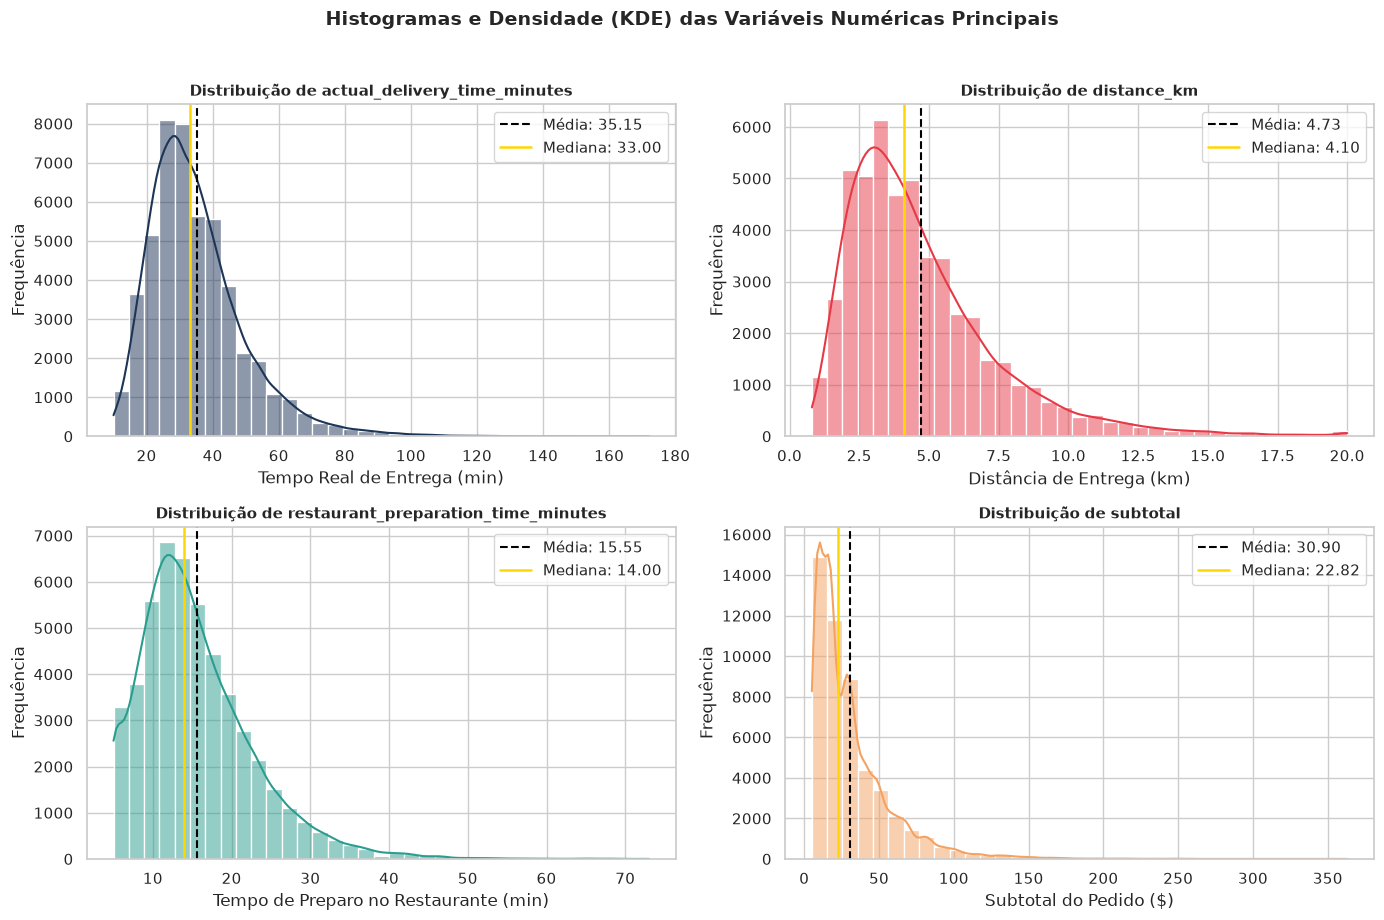

In [9]:
# 1. Histogramas das Principais Variáveis Contínuas
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
hist_specs = [
    ("actual_delivery_time_minutes", "Tempo Real de Entrega (min)", "#1d3557"),
    ("distance_km", "Distância de Entrega (km)", "#e63946"),
    ("restaurant_preparation_time_minutes", "Tempo de Preparo no Restaurante (min)", "#2a9d8f"),
    ("subtotal", "Subtotal do Pedido ($)", "#f4a261")
]

for ax, (col, label, color) in zip(axes.flatten(), hist_specs):
    dados = df[col].dropna()
    sns.histplot(dados, bins=35, kde=True, color=color, ax=ax)
    ax.axvline(dados.mean(), color="black", linestyle="--", linewidth=1.5, label=f"Média: {dados.mean():.2f}")
    ax.axvline(dados.median(), color="gold", linestyle="-", linewidth=1.8, label=f"Mediana: {dados.median():.2f}")
    ax.set_title(f"Distribuição de {col}", fontsize=11, fontweight="bold")
    ax.set_xlabel(label)
    ax.set_ylabel("Frequência")
    ax.legend()

plt.suptitle("Histogramas e Densidade (KDE) das Variáveis Numéricas Principais", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/eda_histograms.png", dpi=300, bbox_inches="tight")
plt.show()


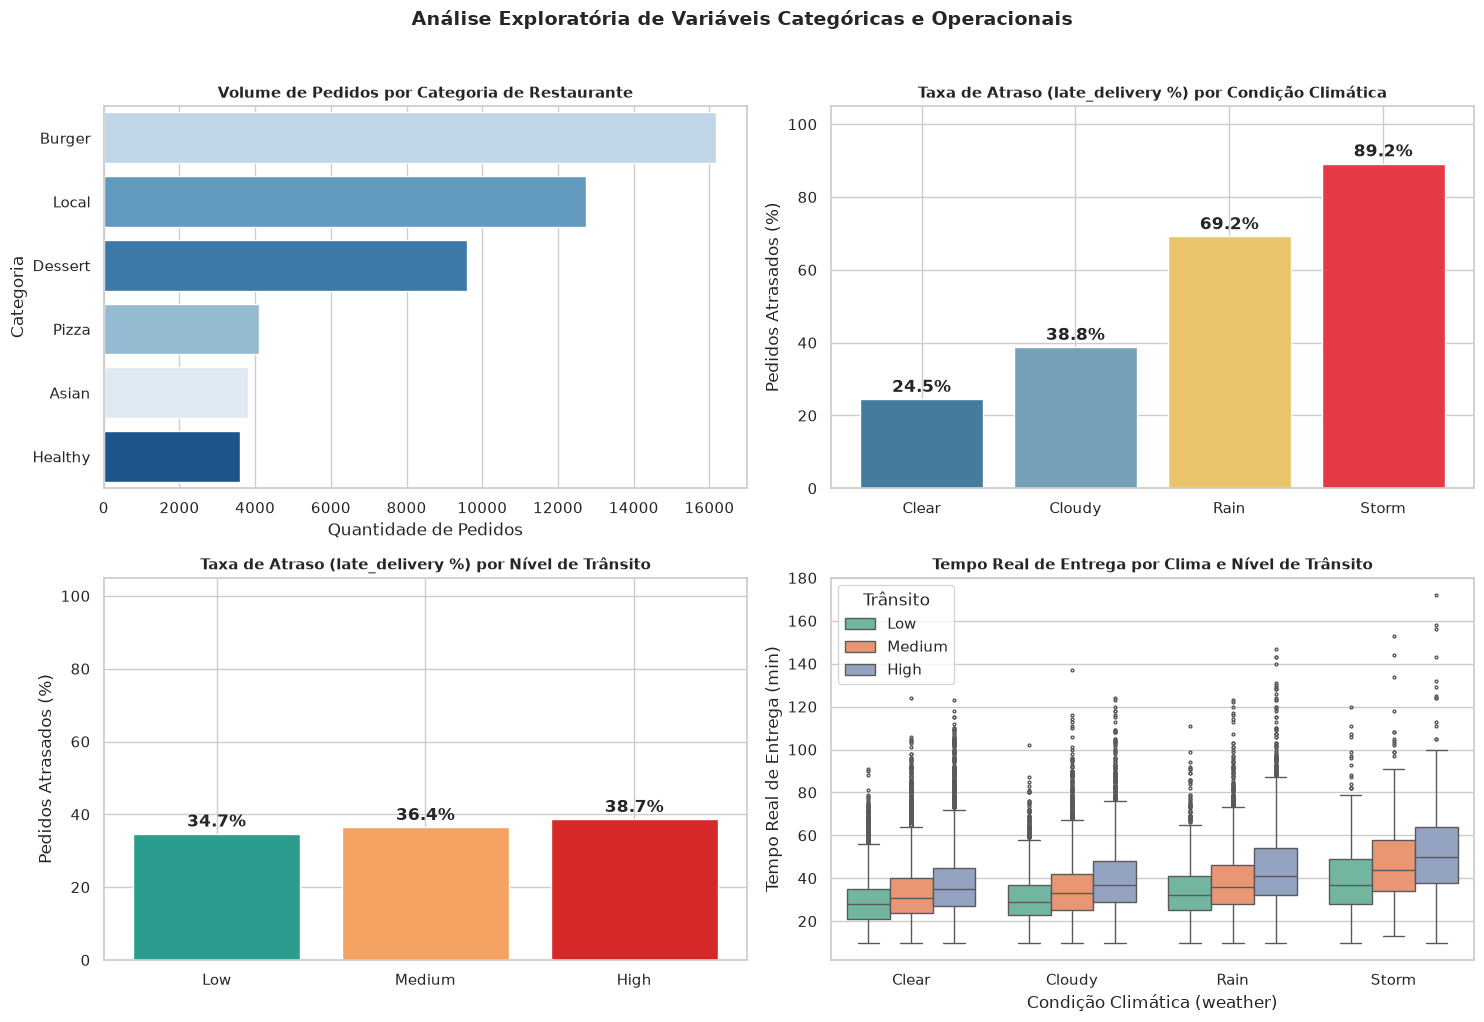

In [10]:
# 2. Análise das Variáveis Categóricas e Impacto na Taxa de Atraso (late_delivery)
df_entregues = df.dropna(subset=["late_delivery"]).copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) Contagem por Categoria de Restaurante
ordem_cat = df["restaurant_primary_category"].value_counts().index
sns.countplot(
    data=df, y="restaurant_primary_category", order=ordem_cat,
    hue="restaurant_primary_category", palette="Blues_r", legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Volume de Pedidos por Categoria de Restaurante", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Quantidade de Pedidos")
axes[0, 0].set_ylabel("Categoria")

# (b) Contagem e Proporção por Condição Climática (weather)
ordem_weather = ["Clear", "Cloudy", "Rain", "Storm"]
taxa_weather = (df_entregues.groupby("weather")["late_delivery"].mean().reindex(ordem_weather) * 100)
bars_w = axes[0, 1].bar(ordem_weather, taxa_weather.values, color=["#457b9d", "#74a0b8", "#e9c46a", "#e63946"])
axes[0, 1].set_title("Taxa de Atraso (late_delivery %) por Condição Climática", fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("Pedidos Atrasados (%)")
axes[0, 1].set_ylim(0, 105)
for b in bars_w:
    h = b.get_height()
    axes[0, 1].text(b.get_x() + b.get_width()/2, h + 2, f"{h:.1f}%", ha="center", fontweight="bold")

# (c) Taxa de Atraso por Nível de Trânsito (traffic_level)
ordem_traffic = ["Low", "Medium", "High"]
taxa_traffic = (df_entregues.groupby("traffic_level")["late_delivery"].mean().reindex(ordem_traffic) * 100)
bars_t = axes[1, 0].bar(ordem_traffic, taxa_traffic.values, color=["#2a9d8f", "#f4a261", "#d62828"])
axes[1, 0].set_title("Taxa de Atraso (late_delivery %) por Nível de Trânsito", fontsize=11, fontweight="bold")
axes[1, 0].set_ylabel("Pedidos Atrasados (%)")
axes[1, 0].set_ylim(0, 105)
for b in bars_t:
    h = b.get_height()
    axes[1, 0].text(b.get_x() + b.get_width()/2, h + 2, f"{h:.1f}%", ha="center", fontweight="bold")

# (d) Boxplot do Tempo Real de Entrega por Clima e Trânsito
sns.boxplot(
    data=df_entregues, x="weather", y="actual_delivery_time_minutes",
    hue="traffic_level", order=ordem_weather, hue_order=ordem_traffic,
    palette="Set2", fliersize=2, ax=axes[1, 1]
)
axes[1, 1].set_title("Tempo Real de Entrega por Clima e Nível de Trânsito", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Condição Climática (weather)")
axes[1, 1].set_ylabel("Tempo Real de Entrega (min)")
axes[1, 1].legend(title="Trânsito")

plt.suptitle("Análise Exploratória de Variáveis Categóricas e Operacionais", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/eda_categorical_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

# Salva também a figura individual de categorias de restaurante para compatibilidade
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df, y="restaurant_primary_category", order=ordem_cat,
    hue="restaurant_primary_category", palette="Blues_r", legend=False
)
plt.title("Contagem de Pedidos por Categoria de Restaurante", fontsize=12, fontweight="bold")
plt.xlabel("Quantidade de Pedidos")
plt.ylabel("Categoria Principal")
plt.tight_layout()
plt.savefig("../reports/figures/restaurant_categories.png", dpi=300)
plt.close()


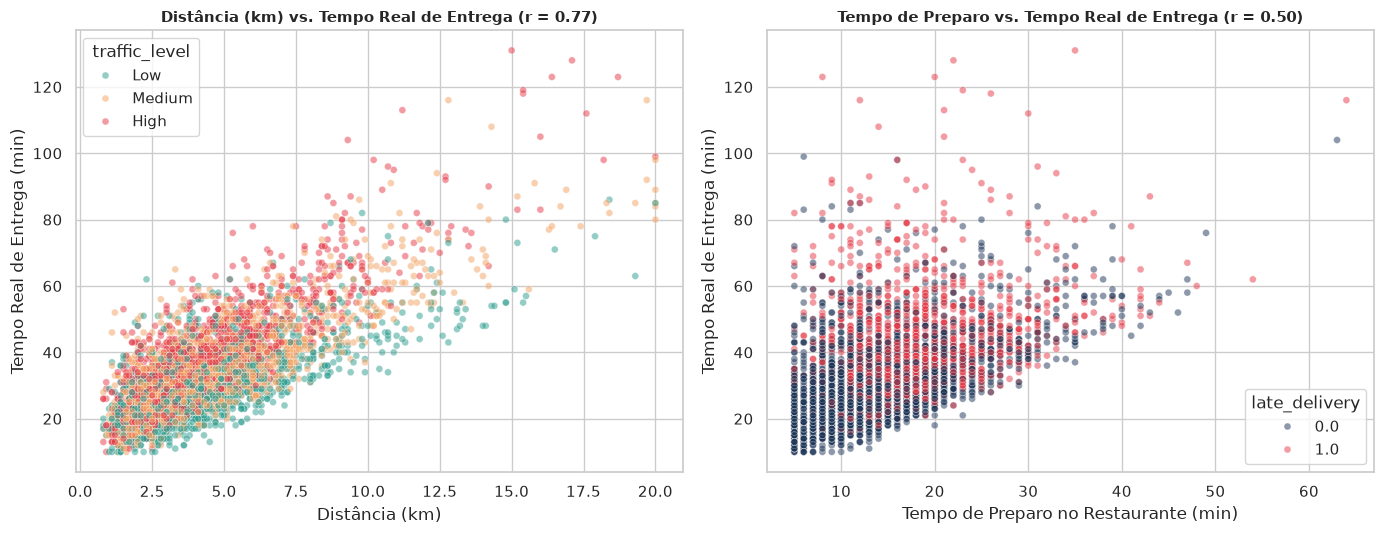

In [11]:
# 3. Relação Bivariada: Distância e Tempo de Preparo vs. Tempo Real de Entrega
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

amostra = df_entregues.sample(n=4000, random_state=42)
sns.scatterplot(
    data=amostra, x="distance_km", y="actual_delivery_time_minutes",
    hue="traffic_level", hue_order=["Low", "Medium", "High"],
    palette={"Low": "#2a9d8f", "Medium": "#f4a261", "High": "#e63946"},
    alpha=0.5, s=25, ax=axes[0]
)
axes[0].set_title("Distância (km) vs. Tempo Real de Entrega (r = 0.77)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Distância (km)")
axes[0].set_ylabel("Tempo Real de Entrega (min)")

sns.scatterplot(
    data=amostra, x="restaurant_preparation_time_minutes", y="actual_delivery_time_minutes",
    hue="late_delivery", palette={0.0: "#1d3557", 1.0: "#e63946"},
    alpha=0.5, s=25, ax=axes[1]
)
axes[1].set_title("Tempo de Preparo vs. Tempo Real de Entrega (r = 0.50)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Tempo de Preparo no Restaurante (min)")
axes[1].set_ylabel("Tempo Real de Entrega (min)")

plt.tight_layout()
plt.savefig("../reports/figures/regression_scatter.png", dpi=300)
plt.show()
